In [2]:
import logging

import numpy as np
import optimistix as optx
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)

Atmodeller initialized with double precision (float64)


# Sub-Neptune (e.g. K2-18b) models from Bower et al. (2025)

The code blocks below must always be run, but then you can preferentially run only the models for ideal or real gases.

Parameters for the simulations

In [3]:
number_of_realisations = 100
surface_temperature = 3000  # K

# For simulations with fixed mass and surface radius:
planet_mass = 5.154e25 
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018
mantle_melt_fraction = 1  # 0.1

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

In [4]:
solubility_models = get_solubility_models()

H2O_g = Species.create_gas("H2O", solubility=solubility_models["H2O_basalt_dixon95"])
H2_g = Species.create_gas("H2", solubility=solubility_models["H2_basalt_hirschmann12"])
O2_g = Species.create_gas("O2")
CO_g = Species.create_gas("CO", solubility=solubility_models["CO_basalt_yoshioka19"])
CO2_g = Species.create_gas("CO2", solubility=solubility_models["CO2_basalt_dixon95"])
CH4_g = Species.create_gas("CH4", solubility=solubility_models["CH4_basalt_ardia13"])

idealspecies_withsols = SpeciesCollection((H2O_g, H2_g, O2_g, CO_g, CO2_g, CH4_g))

In [5]:
eos_models = get_eos_models()

H2O_rg = Species.create_gas(
    "H2O",
    activity=eos_models["H2O_cork_holland98"],
    solubility=solubility_models["H2O_basalt_dixon95"],
)
H2_rg = Species.create_gas(
    "H2",
    activity=eos_models["H2_chabrier21"],
    solubility=solubility_models["H2_basalt_hirschmann12"],
)
O2_rg = Species.create_gas("O2", activity=eos_models["O2_cs_shi92"])
CO_rg = Species.create_gas(
    "CO",
    activity=eos_models["CO_cs_shi92"],
    solubility=solubility_models["CO_basalt_yoshioka19"],
)
CO2_rg = Species.create_gas(
    "CO2",
    activity=eos_models["CO2_cs_shi92"],
    solubility=solubility_models["CO2_basalt_dixon95"],
)
CH4_rg = Species.create_gas(
    "CH4",
    activity=eos_models["CH4_cs_shi92"],
    solubility=solubility_models["CH4_basalt_ardia13"],
)

realspecies_withsols = SpeciesCollection((H2O_rg, H2_rg, O2_rg, CO_rg, CO2_rg, CH4_rg))


## f02 fugacity

Where does saturation occur

In [6]:
# Vary Linearly:

def vary_fO2():
    # Vary Linearly:
    fO2_log10_shifts = np.linspace(-6, 3, number_of_realisations)  # IW-6 to IW
    
    
    # Fix Values for Linearly Varying Cases:
    log10_H_frac = np.full(number_of_realisations, 0)  # 1% of planet mass
    log10_ch_ratios = np.full(number_of_realisations, -0.5)  # 100X Solar
    
    h_kg = ((10**log10_H_frac) / 100) * planet_mass
    c_kg = h_kg * 10**log10_ch_ratios
    
    mass_constraints = {
        "H": h_kg,
        "C": c_kg,
    }

    lijstje = []
    lijstje.append(mass_constraints)
    lijstje.append(fO2_log10_shifts)
    
    return lijstje


In [7]:
def make_planet(surface_temperature, planet_mass, surface_radius, mantle_melt_fraction):
    sub_neptune = Planet(
        surface_temperature=surface_temperature,
        planet_mass=planet_mass,
        surface_radius=surface_radius,
        mantle_melt_fraction=mantle_melt_fraction,
    )
    return sub_neptune

In [8]:
def solve_the_model(sub_neptune, H_RESULTS, species):

    mass_constraints = H_RESULTS[0]
    fO2_log10_shifts = H_RESULTS[1]
    
    solver = optx.LevenbergMarquardt
    solver_parameters = SolverParameters(solver=solver)
    
    model_ideal_varyfO2_withsol = InteriorAtmosphere(species)
    
    fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}
    
    model_ideal_varyfO2_withsol.solve(
        planet=sub_neptune,
        mass_constraints=mass_constraints,
        fugacity_constraints=fugacity_constraints,
        solver_parameters=solver_parameters,
    )
    output_ideal_varyfO2_withsol = model_ideal_varyfO2_withsol.output
    
    # Write the complete solution to Excel
    file = output_ideal_varyfO2_withsol.to_excel("FILE3")
    
    # Write the data to a pickle file with dataframes
    output_ideal_varyfO2_withsol.to_pickle("FILE3")

    return file

In [35]:
def calculate_values(file, real=True):
    
    file = 'FILE3.xlsx'
    
    # === Load sheets ===
    planet = pd.read_excel(file, sheet_name='planet')
    atmosphere = pd.read_excel(file, sheet_name='atmosphere')
    element_H = pd.read_excel(file, sheet_name='element_H')
    element_C = pd.read_excel(file, sheet_name='element_C')
    element_O = pd.read_excel(file, sheet_name='element_O')
    molecule_CO2 = pd.read_excel(file, sheet_name='CO2_g')
    molecule_CO = pd.read_excel(file, sheet_name='CO_g')
    molecule_H2 = pd.read_excel(file, sheet_name='H2_g')
    molecule_CH4 = pd.read_excel(file, sheet_name='CH4_g')
    molecule_H2O = pd.read_excel(file, sheet_name='H2O_g')

    lijst = []

    # 1. Hydrogen fraction (dissolved / total)
    H_diss = element_H['dissolved_moles']
    H_total = element_H['total_moles']
    H_frac = H_diss / H_total
    lijst.append(H_frac)

    # 2. C/O ratio
    C_moles = element_C['atmosphere_moles']
    O_moles = element_O['atmosphere_moles']
    C_O_ratio = C_moles / O_moles
    lijst.append(C_O_ratio)

    # 3. CO₂/CO ratio
    CO2_moles = molecule_CO2['atmosphere_moles']
    CO_moles = molecule_CO['atmosphere_moles']
    CO_CO2_ratio = CO_moles / CO2_moles
    lijst.append(CO_CO2_ratio)

    # 4. CH₄/CO₂ ratio
    CH4_moles = molecule_CH4['atmosphere_moles']
    CH4_CO2_ratio = CH4_moles / CO2_moles
    lijst.append(CH4_CO2_ratio)

    # 5. H₂ dissolved fraction
    H2_diss = molecule_H2['dissolved_moles']
    H2_total = molecule_H2['total_moles']
    H2_frac = H2_diss / H2_total
    lijst.append(H2_frac)

    # 6. Fugacity H₂
    if real and 'fugacity' in molecule_H2.columns:
        fugacity = molecule_H2['fugacity']
        lijst.append(fugacity)

    # 7. Add H₂_diss directly
    H2_atm = molecule_H2['atmosphere_moles']
    surface_pressure = atmosphere['pressure']
    lijst.append([H2_diss, H2_atm, H2_total, surface_pressure])
    
    # 8. Rate of change in dissolved ppmw
    total_mass = molecule_H2['total_mass']

    # Finite differences for derivative
    dH2_diss = np.gradient(H2_diss)
    dmass = np.gradient(total_mass)
    rate_change_ppmw = dH2_diss / dmass
    lijst.append(rate_change_ppmw)

    H2O_total_mass = molecule_H2O['total_mass']
    H2_total_mass = molecule_H2['total_mass']
    H2O_H2_ratio = H2O_total_mass / H2_total_mass
    lijst.append(H2O_H2_ratio)

    H2O_dissolved_mass = molecule_H2O['dissolved_mass']
    H2O_total_mass = H2O_total_mass = molecule_H2O['total_mass']
    H2O_diss_frac = H2O_dissolved_mass / H2O_total_mass
    lijst.append(H2O_diss_frac)

    H_dissolved_mass = element_H['dissolved_mass']
    planet_mass = planet['planet_mass']
    H_dissolved_rel_to_PM = H_dissolved_mass / planet_mass
    lijst.append(H_dissolved_rel_to_PM)

    C_dissolved_mass = element_C['dissolved_mass']
    planet_mass = planet['planet_mass']
    C_dissolved_rel_to_PM = C_dissolved_mass / planet_mass
    lijst.append(C_dissolved_rel_to_PM)

    O_moles = element_O['atmosphere_moles']
    H_moles = element_H['atmosphere_moles']
    O_H_ratio = O_moles / H_moles
    lijst.append(O_H_ratio)
    
    return lijst

In [43]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
from scipy.signal import savgol_filter

def print_plots(H_RESULTS, planet_mass, values, real):
    mass_constraints = H_RESULTS[0]
    fugacity_constraints = H_RESULTS[1]

    fig = plt.figure(figsize=(30, 60))
    gs = gridspec.GridSpec(7, 2, wspace=0.35, hspace=0.45)
    axes = [fig.add_subplot(gs[i]) for i in range(13)]

    x = fugacity_constraints

    # --- Unpack data from lijst ---
    H_frac, C_O, CO2_CO, CH4_CO2, H2_frac, fugacity_H2, H2_partition, rate_change, H2O_ratio, H2O_diss_frac, H_dissolved_rel_to_PM, C_dissolved_rel_to_PM, O_H_ratio = values

    # Expect H2_partition = (H2_diss, H2_atm, H2_total, surface_pressure)
    y_data = {
        'H_frac': H_frac,
        'C/O': C_O,
        'CO₂/CO': CO2_CO,
        'CH₄/CO₂': CH4_CO2,
        'H₂_frac': H2_frac,
        'Fugacity H₂': fugacity_H2,
        'H₂ Partition': H2_partition,
        'Rate of Change in Dissolved ppmw': rate_change,
        'H₂O/H₂ Mass Ratio': H2O_ratio,
        'H₂O Dissolved Fraction': H2O_diss_frac,
        'Hydrogen dissolved relative to planet mass': H_dissolved_rel_to_PM,
        'Carbon dissolved relative to planet mass': C_dissolved_rel_to_PM,
        'O/H': O_H_ratio,
    }

    results = {}
    sat_x, oversat_x, y_min = saturation_calculator(H_RESULTS, planet_mass, y_data['H_frac'])

    # --- Plot loop ---
    for (label, y), ax in zip(y_data.items(), axes):
        if label == 'H₂ Partition':
            # Unpack all four arrays
            y_diss, y_atm, y_total, surface_pressure = y

            # Left axis (H₂ values)
            ax.plot(x, y_diss, 'o-', lw=2, ms=1, color='tab:blue', label='H₂ Dissolved')
            ax.plot(x, y_atm, 's-', lw=2, ms=1, color='tab:orange', label='H₂ Atmosphere')
            ax.plot(x, y_total, '^-', lw=2, ms=1, color='tab:green', label='H₂ Total')

            ax.set_xscale('log')
            ax.set_yscale('log')
            ax.set_xlabel('Total H fraction (wt% planet)')
            ax.set_ylabel('H₂ Moles (log scale)')
            ax.set_title('H₂ Partition & Surface Pressure')
            ax.grid(alpha=0.3)

            # Right axis (surface pressure)
            ax2 = ax.twinx()
            ax2.plot(x, surface_pressure, 'D--', lw=2, ms=1, color='black', label='Surface Pressure')
            ax2.set_yscale('log')
            ax2.set_ylabel('Surface Pressure (bar)', color='black')
            ax2.tick_params(axis='y', labelcolor='black')

            # Combined legend
            lines, labels = ax.get_legend_handles_labels()
            lines2, labels2 = ax2.get_legend_handles_labels()
            ax2.legend(lines + lines2, labels + labels2, loc='best', fontsize=8)

            continue

        if label == 'O/H':
            # --- Custom final scatterplot: O/H (x) vs C/O (y) ---
            O_H = np.array(O_H_ratio)
            C_over_O = np.array(y_data['C/O'])
        
            # Scatter
            ax.scatter(O_H, C_over_O, s=20)
        
            # Best-fit line
            #m, b = np.polyfit(O_H, C_over_O, 1)
            #ax.plot(O_H, m * O_H + b)
        
            ax.set_xlabel("O/H")
            ax.set_ylabel("C/O")
            ax.set_title("Correlation: C/O vs O/H")
            ax.grid(alpha=0.3)
        
            continue

        # --- Normal plots ---
        y = np.array(y)
        ax.plot(x, y, 'o-', lw=2, ms=3)
        ax.set_xscale('log')
        ax.set_xlabel('Total H fraction (wt% planet)')
        ax.set_ylabel(label)
        ax.set_title(label)
        ax.grid(alpha=0.3)

        # Log scaling for specific plots
        if label in ['CH₄/CO₂', 'C/O', 'CO₂/CO', 'Fugacity H₂', 'Rate of Change in Dissolved ppmw', 'Hydrogen dissolved relative to planet mass', 'Carbon dissolved relative to planet mass']:
            ax.set_yscale('log')

        # === Saturation detection (H_frac only) ===
        if label == 'H_frac':
            ax.axvline(sat_x, color='purple', ls='--', lw=2, label='Saturation')
            ax.axvline(oversat_x, color='pink', ls='--', lw=2, label='Oversaturation')

        results[label] = {
            'min': (float(x[np.argmin(y)]), float(np.min(y))),
            'max': (float(x[np.argmax(y)]), float(np.max(y)))
        }

    # Mark saturation/oversaturation on all other plots
    for ax in axes[1:]:
        if sat_x:
            ax.axvline(sat_x, color='purple', ls='--', lw=1.2, alpha=0.5)
        if oversat_x:
            ax.axvline(oversat_x, color='pink', ls='--', lw=1.2, alpha=0.5)

    plt.tight_layout()
    plt.savefig('saturation_cliff_full.png', dpi=300)
    plt.show()

    print("\n=== Summary ===")
    for label, vals in results.items():
        print(f"{label}: min at x={vals['min'][0]:.3e}, y={vals['min'][1]:.4e}")
        print(f"        max at x={vals['max'][0]:.3e}, y={vals['max'][1]:.4e}")

    return results


In [44]:
def saturation_calculator(H_RESULTS, planet_mass, y):
    
    mass_constraints = H_RESULTS[0]
    h_kg = np.array(mass_constraints['H'])

    x = h_kg / planet_mass
    sat_x, oversat_x, y_min = None, None, None

    # Saturation: first point where y < 0.98
    sat_candidates = np.where(y < 0.995)[0]
    if len(sat_candidates) > 0:
        sat_x = x[sat_candidates[0]]

    # Oversaturation: minimum of y
    y_min = min(y)
    oversat_x = x[np.argmin(y)]

    return sat_x, oversat_x, y_min


In [45]:
def mass_calculator(radius):
    radiusV = radius / 6378137
    masslist = []
    #if radiusV < 1.5:
    mass_ratio = 1.4 * radiusV**2.3
    mass = 5.97219e24 * mass_ratio
    masslist.append(mass)
    #elif radiusV >= 1.5:
    #mass_ratio = 2.7 * radiusV**1.3
    #mass = 5.97219e24 * mass_ratio
    #masslist.append(mass)
    MASS = masslist[0]
    print(MASS)
    return MASS

In [46]:
def plotter(temperature, radius, mantle, species, real):
    mass = mass_calculator(radius)
    fugacity_range = vary_fO2()
    sub_neptune = make_planet(temperature, mass, radius, mantle)
    solved_model = solve_the_model(sub_neptune, fugacity_range, species)
    values = calculate_values(solved_model, real)
    plots = print_plots(fugacity_range, mass, values, real)
    return plots


In [47]:
def FUNTION_RUNNER(temperature, radius, mantle, species, real):
    return plotter(temperature, radius, mantle, species, real)

        

[13:28:46 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[13:28:46 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[13:28:46 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[13:28:46 - atmodeller.classes             - INFO     ] - Attempting to solve 100 model(s)


8.361066000000001e+24


[13:28:48 - atmodeller.classes             - INFO     ] - Solve complete: 100 (100.00%) successful model(s)
[13:28:48 - atmodeller.classes             - INFO     ] - Solver steps (max) = 63
[13:28:48 - atmodeller.output              - INFO     ] - Writing output to excel
[13:28:48 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[13:28:48 - atmodeller.output_core         - INFO     ] - Computing asdict output
[13:28:48 - atmodeller.output              - INFO     ] - Output written to FILE3.xlsx
[13:28:48 - atmodeller.output              - INFO     ] - Writing output to pickle
[13:28:48 - atmodeller.output              - INFO     ] - Output written to FILE3.pkl
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_81927/3741892254.py:120: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


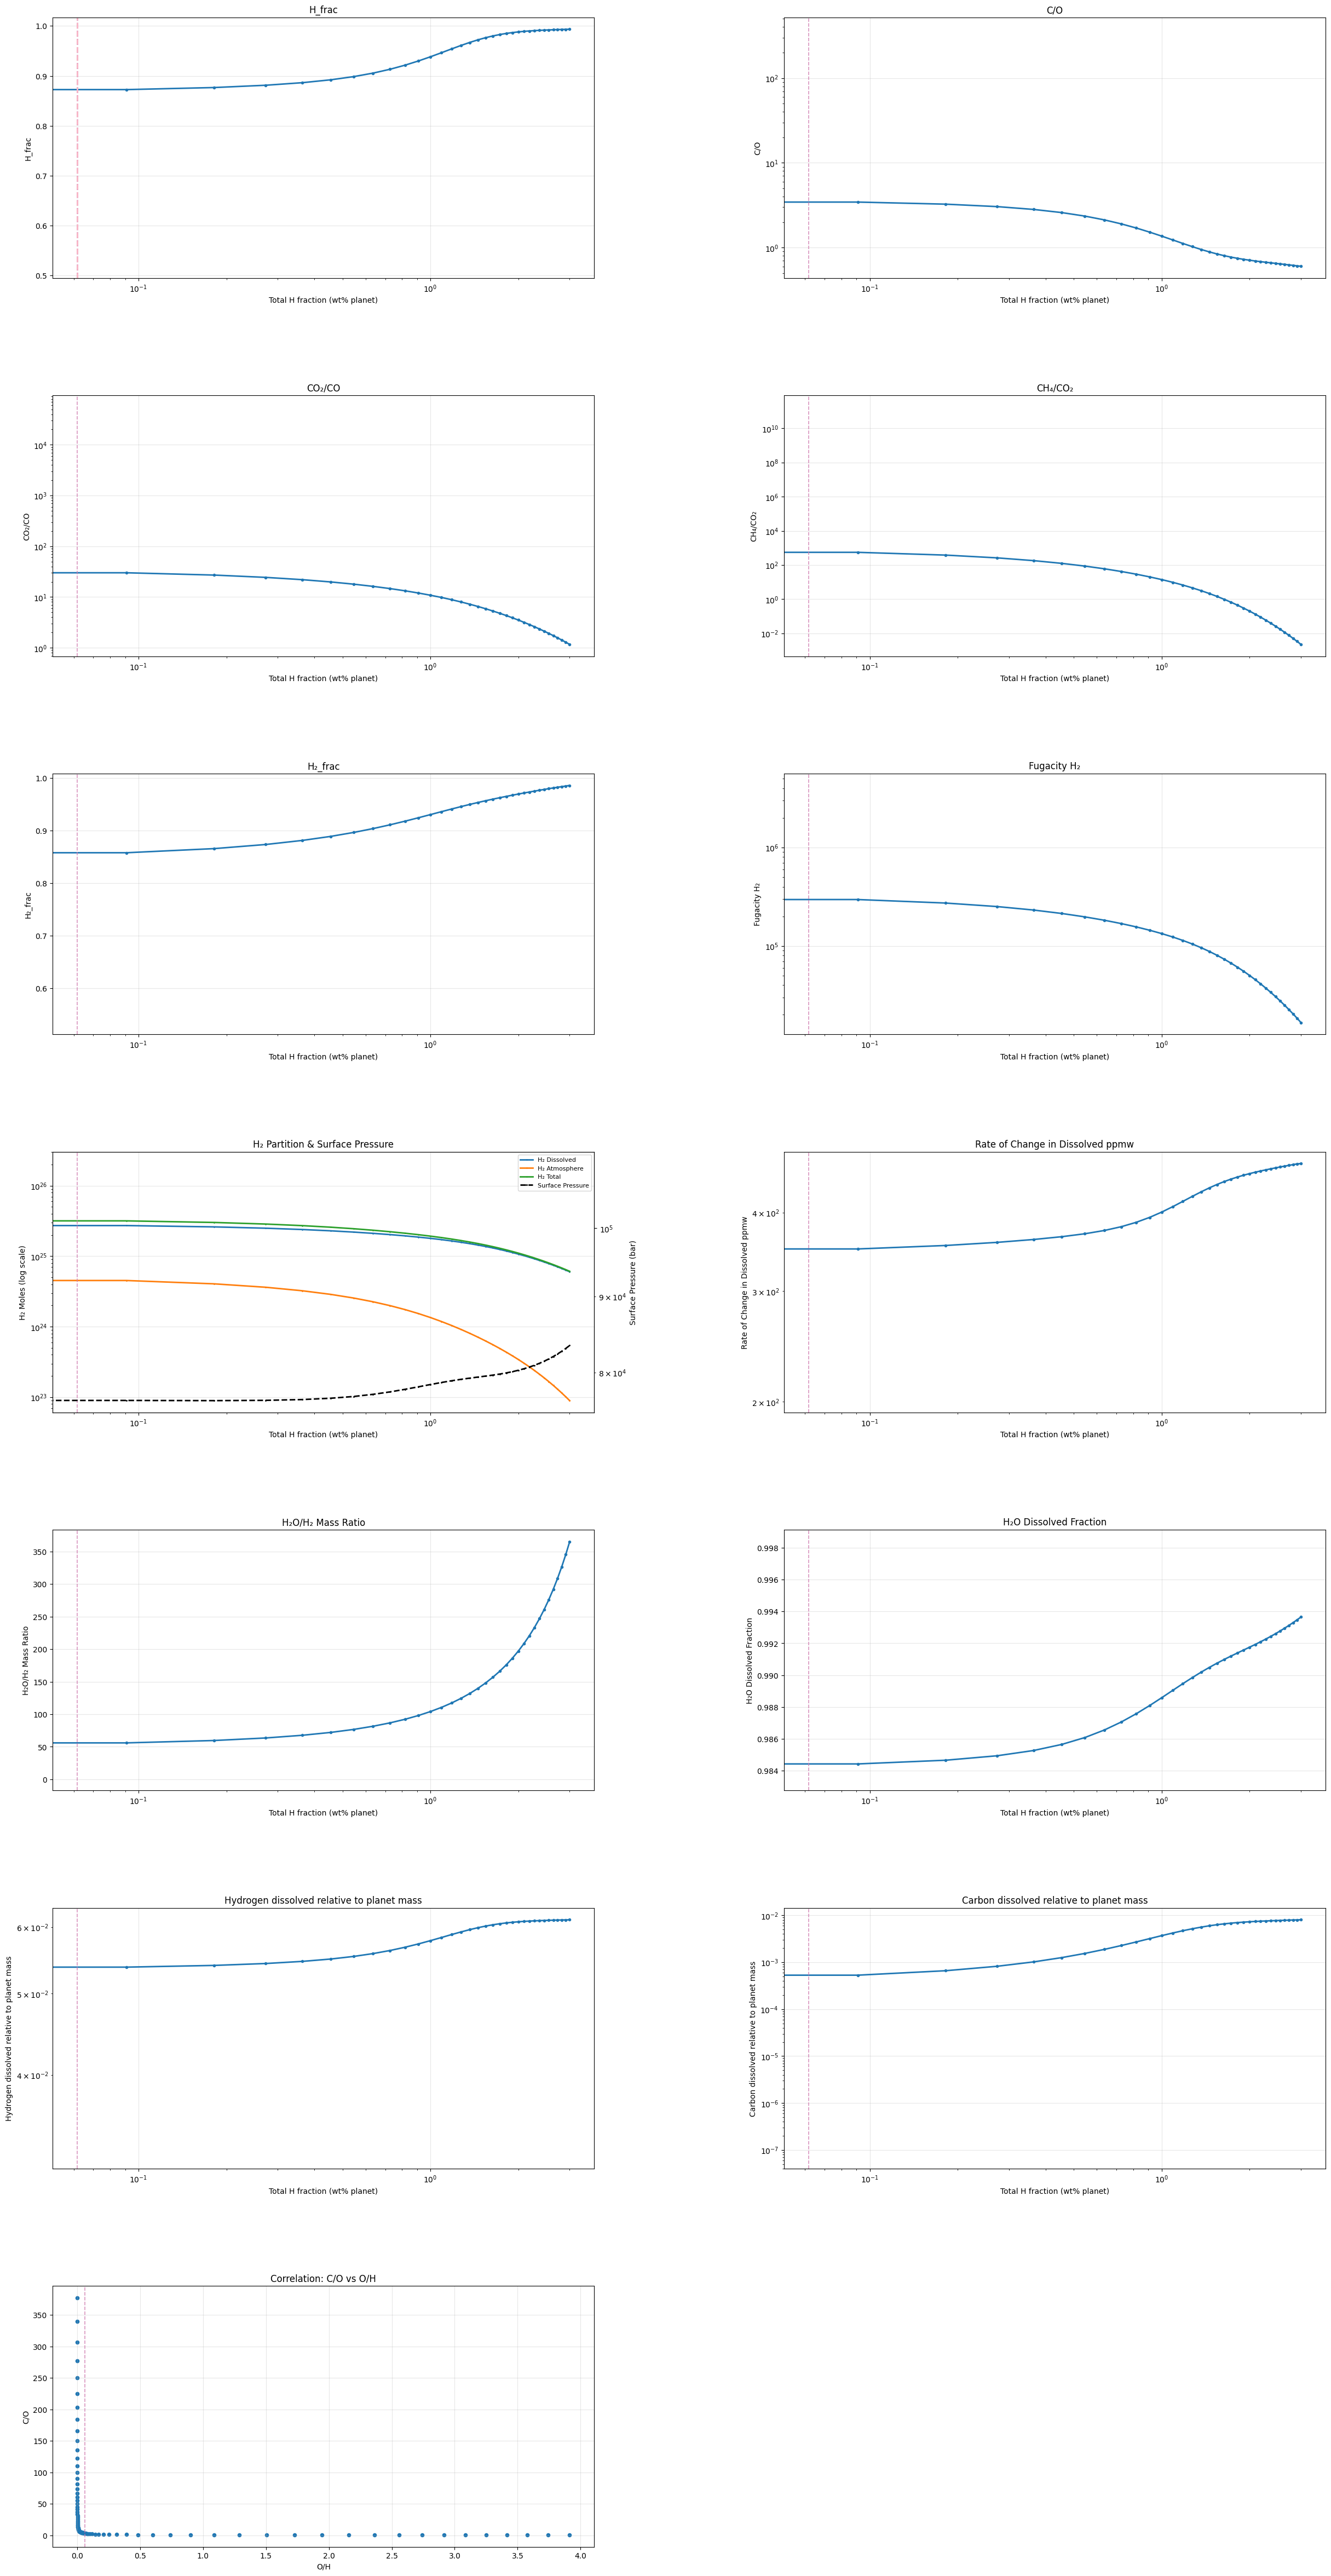


=== Summary ===
H_frac: min at x=-6.000e+00, y=5.1846e-01
        max at x=3.000e+00, y=9.9339e-01
C/O: min at x=3.000e+00, y=6.0297e-01
        max at x=-6.000e+00, y=3.7705e+02
CO₂/CO: min at x=3.000e+00, y=1.1675e+00
        max at x=-6.000e+00, y=5.4598e+04
CH₄/CO₂: min at x=3.000e+00, y=2.2372e-03
        max at x=-6.000e+00, y=1.7055e+11
H₂_frac: min at x=-6.000e+00, y=5.3466e-01
        max at x=3.000e+00, y=9.8536e-01
Fugacity H₂: min at x=3.000e+00, y=1.6689e+04
        max at x=-6.000e+00, y=4.2779e+06
Rate of Change in Dissolved ppmw: min at x=-2.455e+00, y=2.0078e+02
        max at x=3.000e+00, y=4.7871e+02
H₂O/H₂ Mass Ratio: min at x=-6.000e+00, y=9.6924e-01
        max at x=3.000e+00, y=3.6489e+02
H₂O Dissolved Fraction: min at x=-9.091e-01, y=9.8348e-01
        max at x=-6.000e+00, y=9.9839e-01
Hydrogen dissolved relative to planet mass: min at x=-6.000e+00, y=3.1959e-02
        max at x=3.000e+00, y=6.1235e-02
Carbon dissolved relative to planet mass: min at x=-6.000e+

{'H_frac': {'min': (-6.0, 0.5184617317286268),
  'max': (3.0, 0.9933898049271047)},
 'C/O': {'min': (3.0, 0.6029718319901634), 'max': (-6.0, 377.05351397307214)},
 'CO₂/CO': {'min': (3.0, 1.1675395771750656),
  'max': (-6.0, 54597.98489515058)},
 'CH₄/CO₂': {'min': (3.0, 0.0022371625228238727),
  'max': (-6.0, 170550570863.97266)},
 'H₂_frac': {'min': (-6.0, 0.5346593294851242),
  'max': (3.0, 0.9853636254918251)},
 'Fugacity H₂': {'min': (3.0, 16688.77607176584),
  'max': (-6.0, 4277869.036078662)},
 'Rate of Change in Dissolved ppmw': {'min': (-2.4545454545454546,
   200.77566958557034),
  'max': (3.0, 478.7102493438798)},
 'H₂O/H₂ Mass Ratio': {'min': (-6.0, 0.9692353054621482),
  'max': (3.0, 364.88973668062226)},
 'H₂O Dissolved Fraction': {'min': (-0.9090909090909092, 0.9834834186027926),
  'max': (-6.0, 0.9983906911819997)},
 'Hydrogen dissolved relative to planet mass': {'min': (-6.0,
   0.031959462642832275),
  'max': (3.0, 0.06123538616491589)},
 'Carbon dissolved relative to

In [48]:
FUNTION_RUNNER(temperature=3000, radius=6378137, mantle=1, species=realspecies_withsols, real=True)

[13:27:54 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[13:27:54 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[13:27:54 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[13:27:54 - atmodeller.classes             - INFO     ] - Attempting to solve 100 model(s)


2.1245724594568143e+25


[13:27:55 - atmodeller.classes             - INFO     ] - Solve complete: 100 (100.00%) successful model(s)
[13:27:55 - atmodeller.classes             - INFO     ] - Solver steps (max) = 53
[13:27:55 - atmodeller.output              - INFO     ] - Writing output to excel
[13:27:55 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[13:27:55 - atmodeller.output_core         - INFO     ] - Computing asdict output
[13:27:55 - atmodeller.output              - INFO     ] - Output written to FILE3.xlsx
[13:27:55 - atmodeller.output              - INFO     ] - Writing output to pickle
[13:27:55 - atmodeller.output              - INFO     ] - Output written to FILE3.pkl
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_81927/2567261459.py:120: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


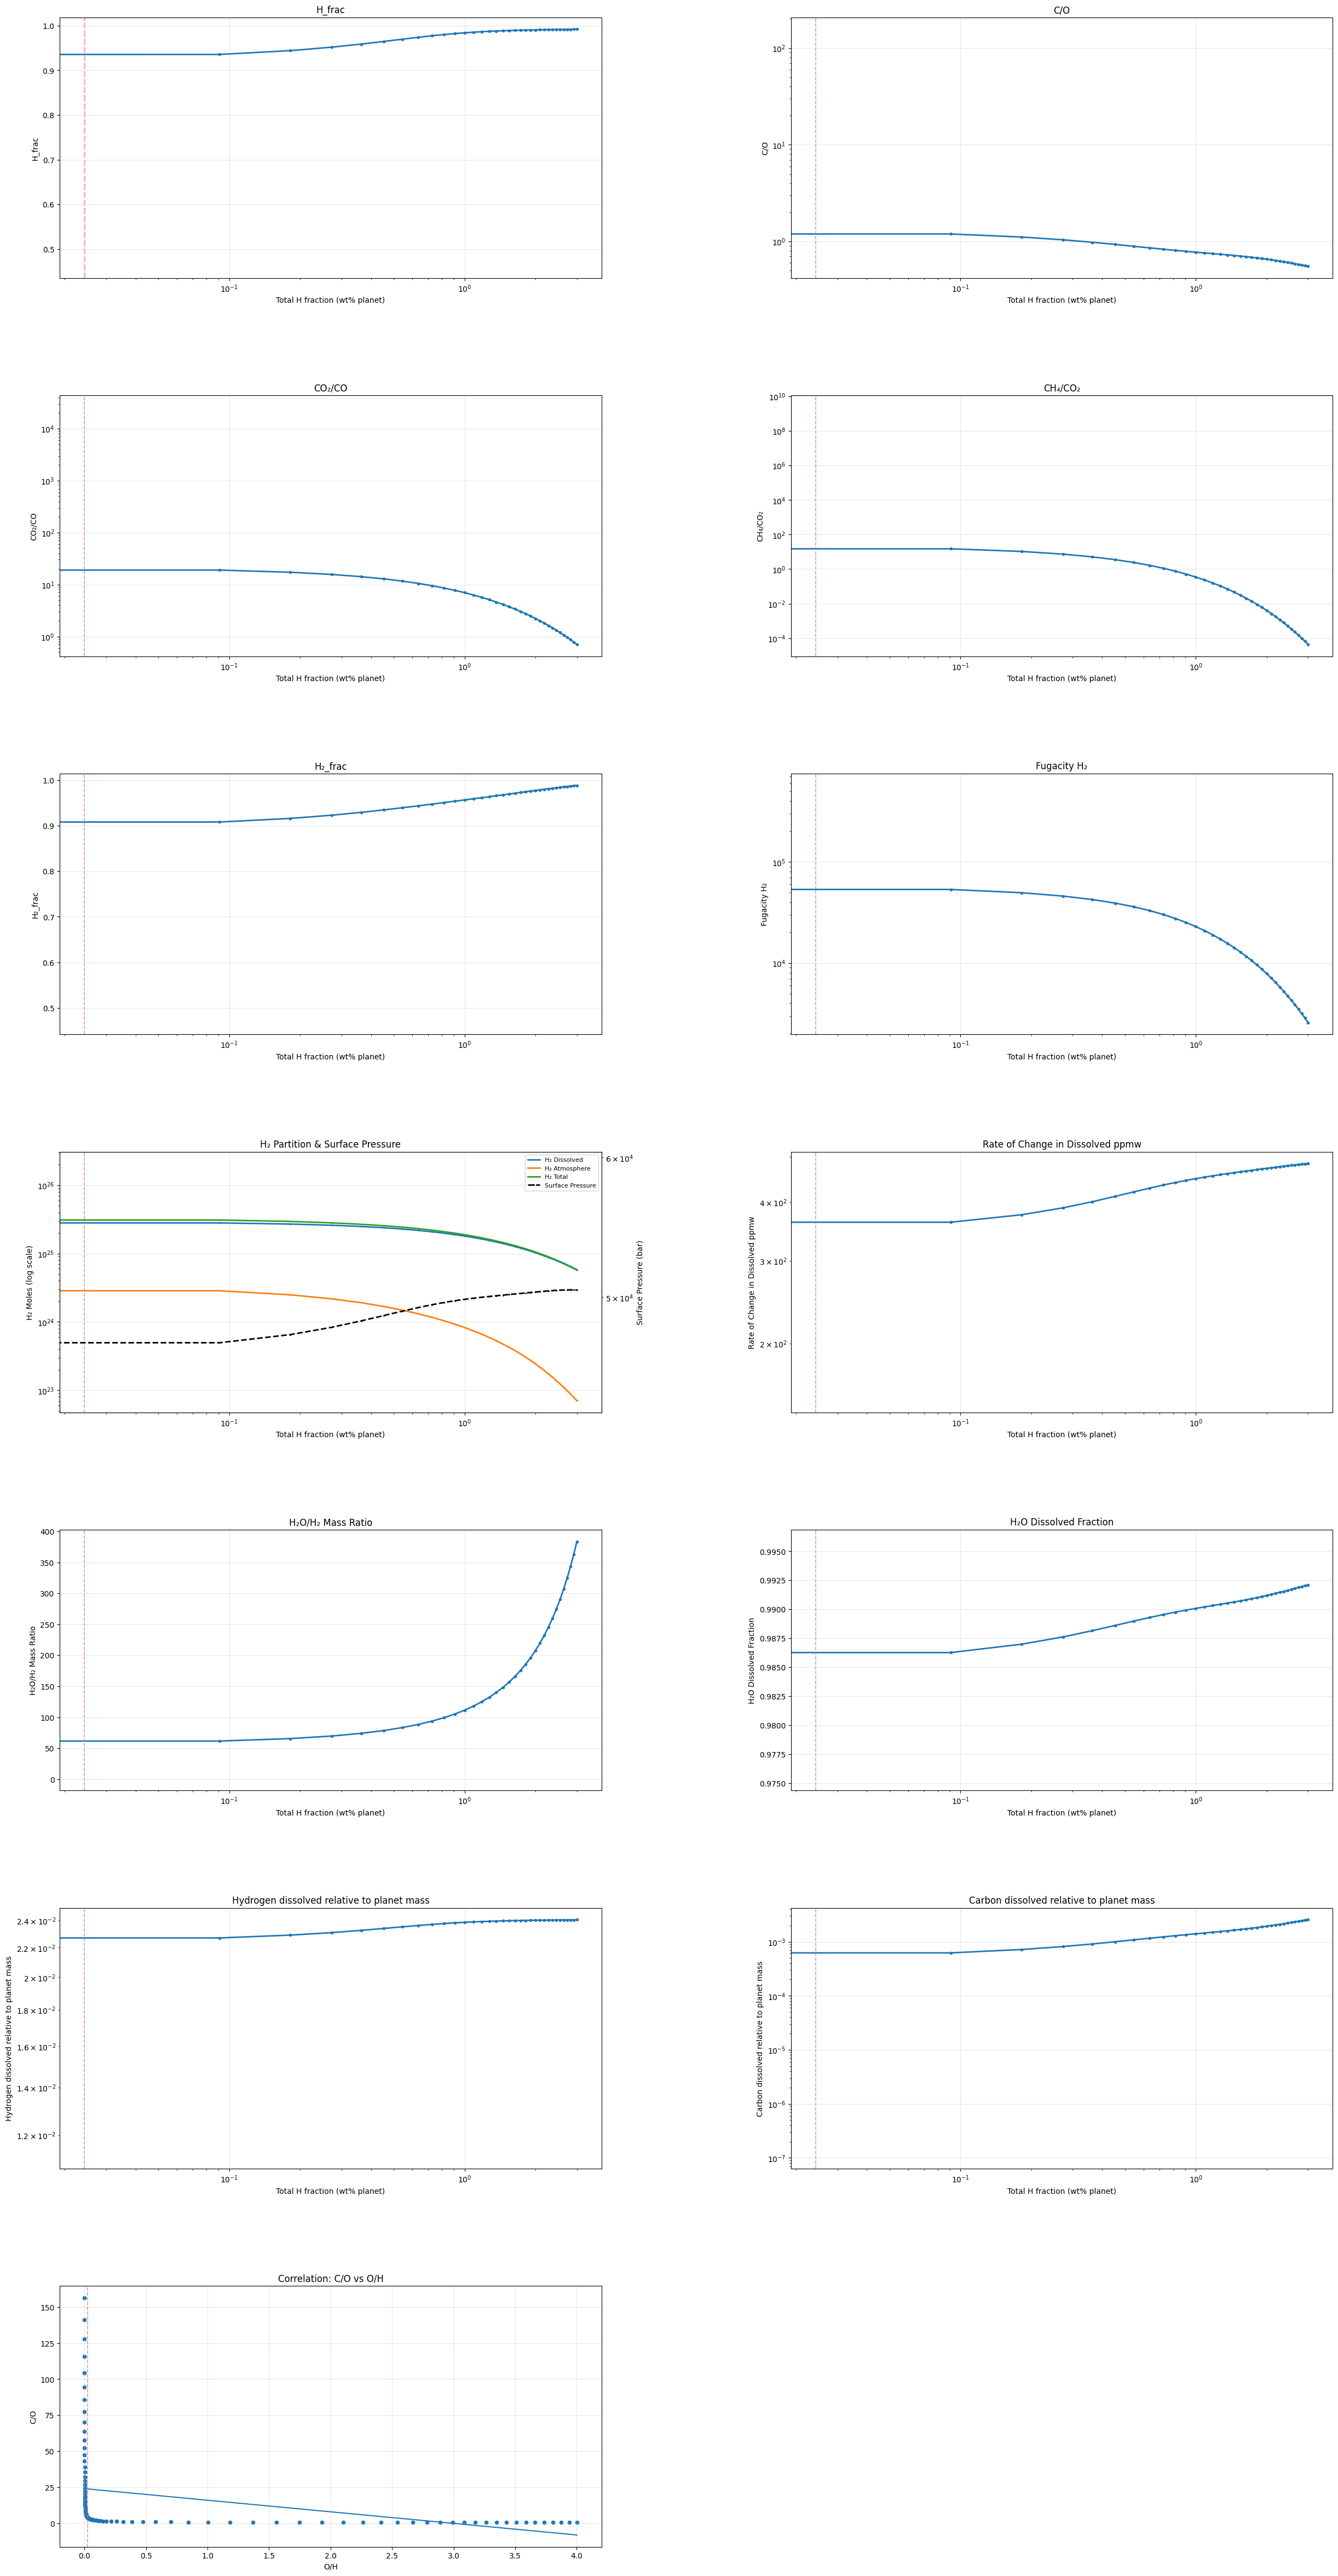


=== Summary ===
H_frac: min at x=-6.000e+00, y=4.6134e-01
        max at x=3.000e+00, y=9.9200e-01
C/O: min at x=3.000e+00, y=5.5434e-01
        max at x=-6.000e+00, y=1.5632e+02
CO₂/CO: min at x=3.000e+00, y=7.0538e-01
        max at x=-6.000e+00, y=2.5769e+04
CH₄/CO₂: min at x=3.000e+00, y=4.4221e-05
        max at x=-6.000e+00, y=2.2660e+09
H₂_frac: min at x=-6.000e+00, y=4.6817e-01
        max at x=3.000e+00, y=9.8790e-01
Fugacity H₂: min at x=3.000e+00, y=2.5829e+03
        max at x=-6.000e+00, y=5.6867e+05
Rate of Change in Dissolved ppmw: min at x=-3.091e+00, y=1.5107e+02
        max at x=3.000e+00, y=4.8326e+02
H₂O/H₂ Mass Ratio: min at x=-6.000e+00, y=8.9337e-01
        max at x=3.000e+00, y=3.8328e+02
H₂O Dissolved Fraction: min at x=-1.727e+00, y=9.7540e-01
        max at x=-6.000e+00, y=9.9583e-01
Hydrogen dissolved relative to planet mass: min at x=-6.000e+00, y=1.1192e-02
        max at x=3.000e+00, y=2.4065e-02
Carbon dissolved relative to planet mass: min at x=-6.000e+

{'H_frac': {'min': (-6.0, 0.4613422914465074),
  'max': (3.0, 0.9920041329789532)},
 'C/O': {'min': (3.0, 0.5543397807118946), 'max': (-6.0, 156.31853265991973)},
 'CO₂/CO': {'min': (3.0, 0.7053818755578131),
  'max': (-6.0, 25768.735428830965)},
 'CH₄/CO₂': {'min': (3.0, 4.422103552654395e-05),
  'max': (-6.0, 2266037476.050877)},
 'H₂_frac': {'min': (-6.0, 0.46817433976163153),
  'max': (3.0, 0.9879002982926649)},
 'Fugacity H₂': {'min': (3.0, 2582.853490268547),
  'max': (-6.0, 568666.6949990551)},
 'Rate of Change in Dissolved ppmw': {'min': (-3.090909090909091,
   151.07174868188824),
  'max': (3.0, 483.25664054013816)},
 'H₂O/H₂ Mass Ratio': {'min': (-6.0, 0.8933690373412788),
  'max': (3.0, 383.2807017961392)},
 'H₂O Dissolved Fraction': {'min': (-1.7272727272727275, 0.975400902628136),
  'max': (-6.0, 0.99582779216114)},
 'Hydrogen dissolved relative to planet mass': {'min': (-6.0,
   0.01119170192643123),
  'max': (3.0, 0.024065026714234862)},
 'Carbon dissolved relative to pl

In [42]:
FUNTION_RUNNER(temperature=3000, radius=6378137 * 1.5, mantle=1, species=realspecies_withsols, real=True)

[21:06:49 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[21:06:49 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[21:06:49 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[21:06:49 - atmodeller.classes             - INFO     ] - Attempting to solve 100 model(s)


4.117471878203249e+25


[21:06:52 - atmodeller.classes             - INFO     ] - Solve complete: 100 (100.00%) successful model(s)
[21:06:52 - atmodeller.classes             - INFO     ] - Solver steps (max) = 123
[21:06:52 - atmodeller.output              - INFO     ] - Writing output to excel
[21:06:52 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[21:06:52 - atmodeller.output_core         - INFO     ] - Computing asdict output
[21:06:52 - atmodeller.output              - INFO     ] - Output written to FILE2.xlsx
[21:06:52 - atmodeller.output              - INFO     ] - Writing output to pickle
[21:06:52 - atmodeller.output              - INFO     ] - Output written to FILE2.pkl
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_76429/3192960051.py:100: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


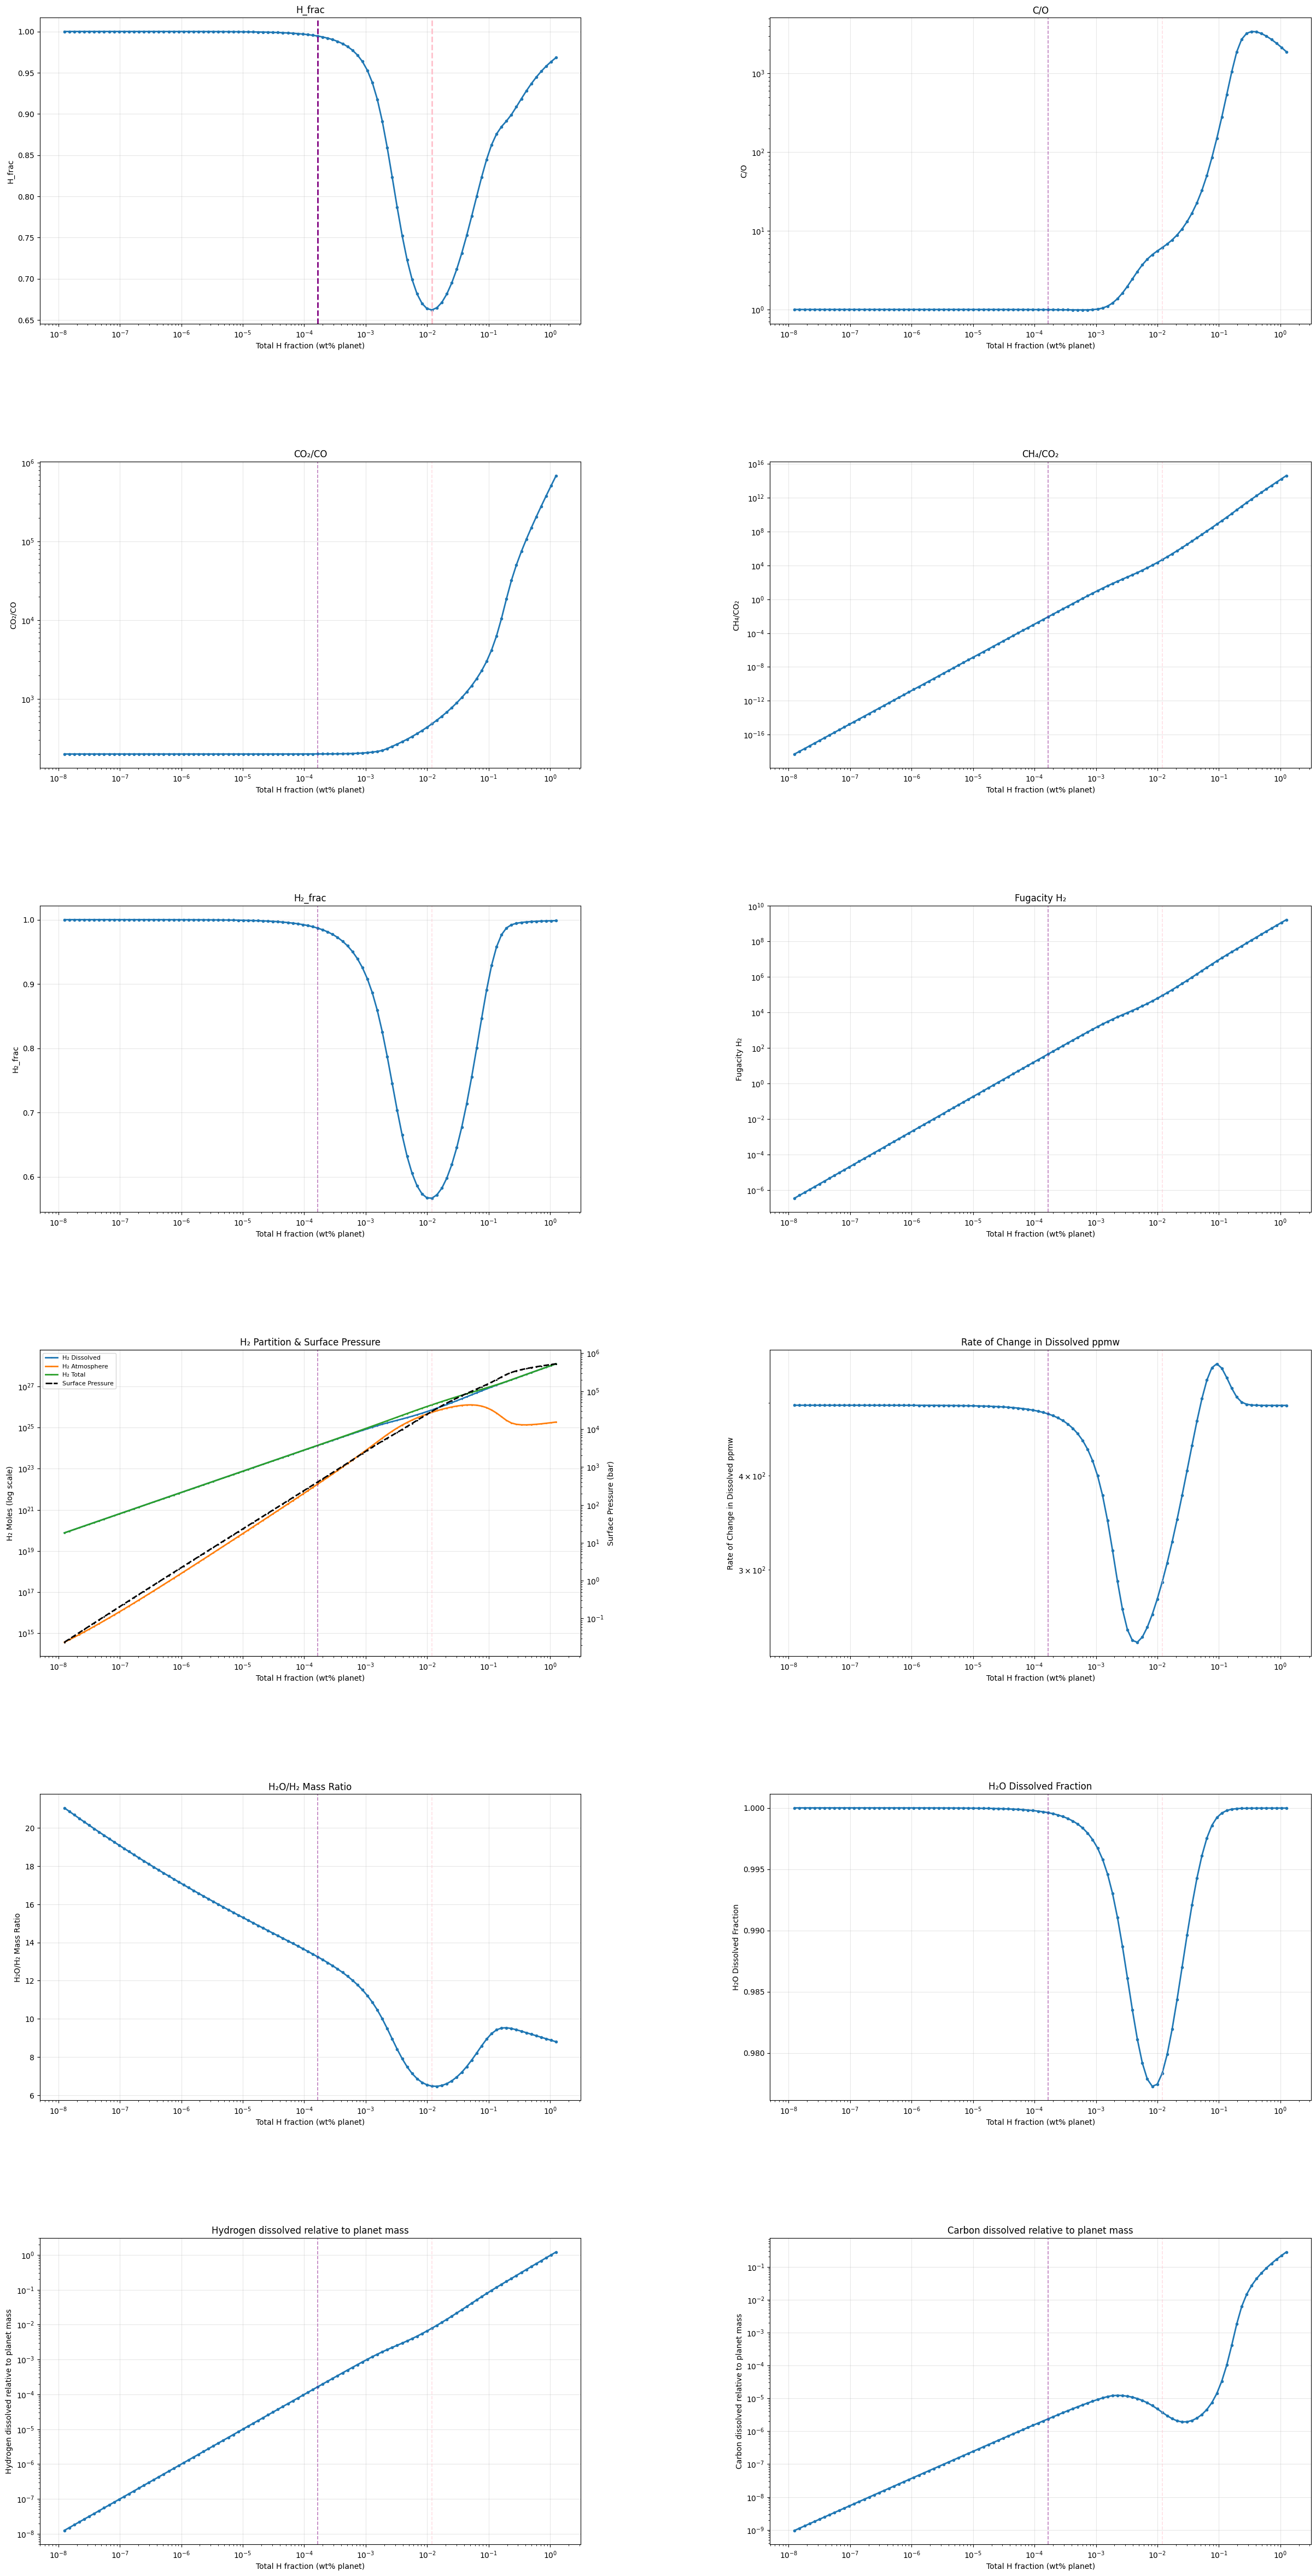


=== Summary ===
H_frac: min at x=1.195e-02, y=6.6206e-01
        max at x=1.252e-08, y=1.0000e+00
C/O: min at x=6.087e-04, y=9.8314e-01
        max at x=3.403e-01, y=3.4193e+03
CO₂/CO: min at x=4.294e-07, y=2.0010e+02
        max at x=1.252e+00, y=6.8760e+05
CH₄/CO₂: min at x=1.252e-08, y=5.0703e-19
        max at x=1.252e+00, y=4.0908e+14
H₂_frac: min at x=1.195e-02, y=5.6683e-01
        max at x=1.252e-08, y=1.0000e+00
Fugacity H₂: min at x=1.252e-08, y=3.6053e-07
        max at x=1.252e+00, y=1.6907e+09
Rate of Change in Dissolved ppmw: min at x=4.713e-03, y=2.4031e+02
        max at x=9.251e-02, y=5.6309e+02
H₂O/H₂ Mass Ratio: min at x=1.439e-02, y=6.4624e+00
        max at x=1.252e-08, y=2.1050e+01
H₂O Dissolved Fraction: min at x=8.236e-03, y=9.7727e-01
        max at x=1.252e-08, y=1.0000e+00
Hydrogen dissolved relative to planet mass: min at x=1.252e-08, y=1.2517e-08
        max at x=1.252e+00, y=1.2121e+00
Carbon dissolved relative to planet mass: min at x=1.252e-08, y=9.6506

{'H_frac': {'min': (0.011948455001426592, 0.6620617278512334),
  'max': (1.2517389680992947e-08, 0.9999985270100936)},
 'C/O': {'min': (0.0006086707884109004, 0.9831371036184212),
  'max': (0.34029628416454116, 3419.2583626933792)},
 'CO₂/CO': {'min': (4.2940520845481605e-07, 200.10017629757414),
  'max': (1.2517389680992947, 687595.0665541043)},
 'CH₄/CO₂': {'min': (1.2517389680992947e-08, 5.070309191398308e-19),
  'max': (1.2517389680992947, 409077058079254.6)},
 'H₂_frac': {'min': (0.011948455001426592, 0.5668281742478191),
  'max': (1.2517389680992947e-08, 0.9999951328624243)},
 'Fugacity H₂': {'min': (1.2517389680992947e-08, 3.605283464543358e-07),
  'max': (1.2517389680992947, 1690713821.836374)},
 'Rate of Change in Dissolved ppmw': {'min': (0.004712716861754494,
   240.30525501301366),
  'max': (0.09251254771754293, 563.0940095601835)},
 'H₂O/H₂ Mass Ratio': {'min': (0.014391956349841101, 6.462444564934163),
  'max': (1.2517389680992947e-08, 21.050111455862936)},
 'H₂O Dissolve

In [36]:
FUNTION_RUNNER(temperature=3000, radius=6378137 * 2, mantle=1, species=realspecies_withsols, real=True)

[21:06:56 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[21:06:56 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[21:06:56 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[21:06:56 - atmodeller.classes             - INFO     ] - Attempting to solve 100 model(s)


1.0462622056826901e+26


[21:06:58 - atmodeller.classes             - INFO     ] - Solve complete: 100 (100.00%) successful model(s)
[21:06:58 - atmodeller.classes             - INFO     ] - Solver steps (max) = 104
[21:06:58 - atmodeller.output              - INFO     ] - Writing output to excel
[21:06:58 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[21:06:58 - atmodeller.output_core         - INFO     ] - Computing asdict output
[21:06:59 - atmodeller.output              - INFO     ] - Output written to FILE2.xlsx
[21:06:59 - atmodeller.output              - INFO     ] - Writing output to pickle
[21:06:59 - atmodeller.output              - INFO     ] - Output written to FILE2.pkl
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_76429/3192960051.py:100: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


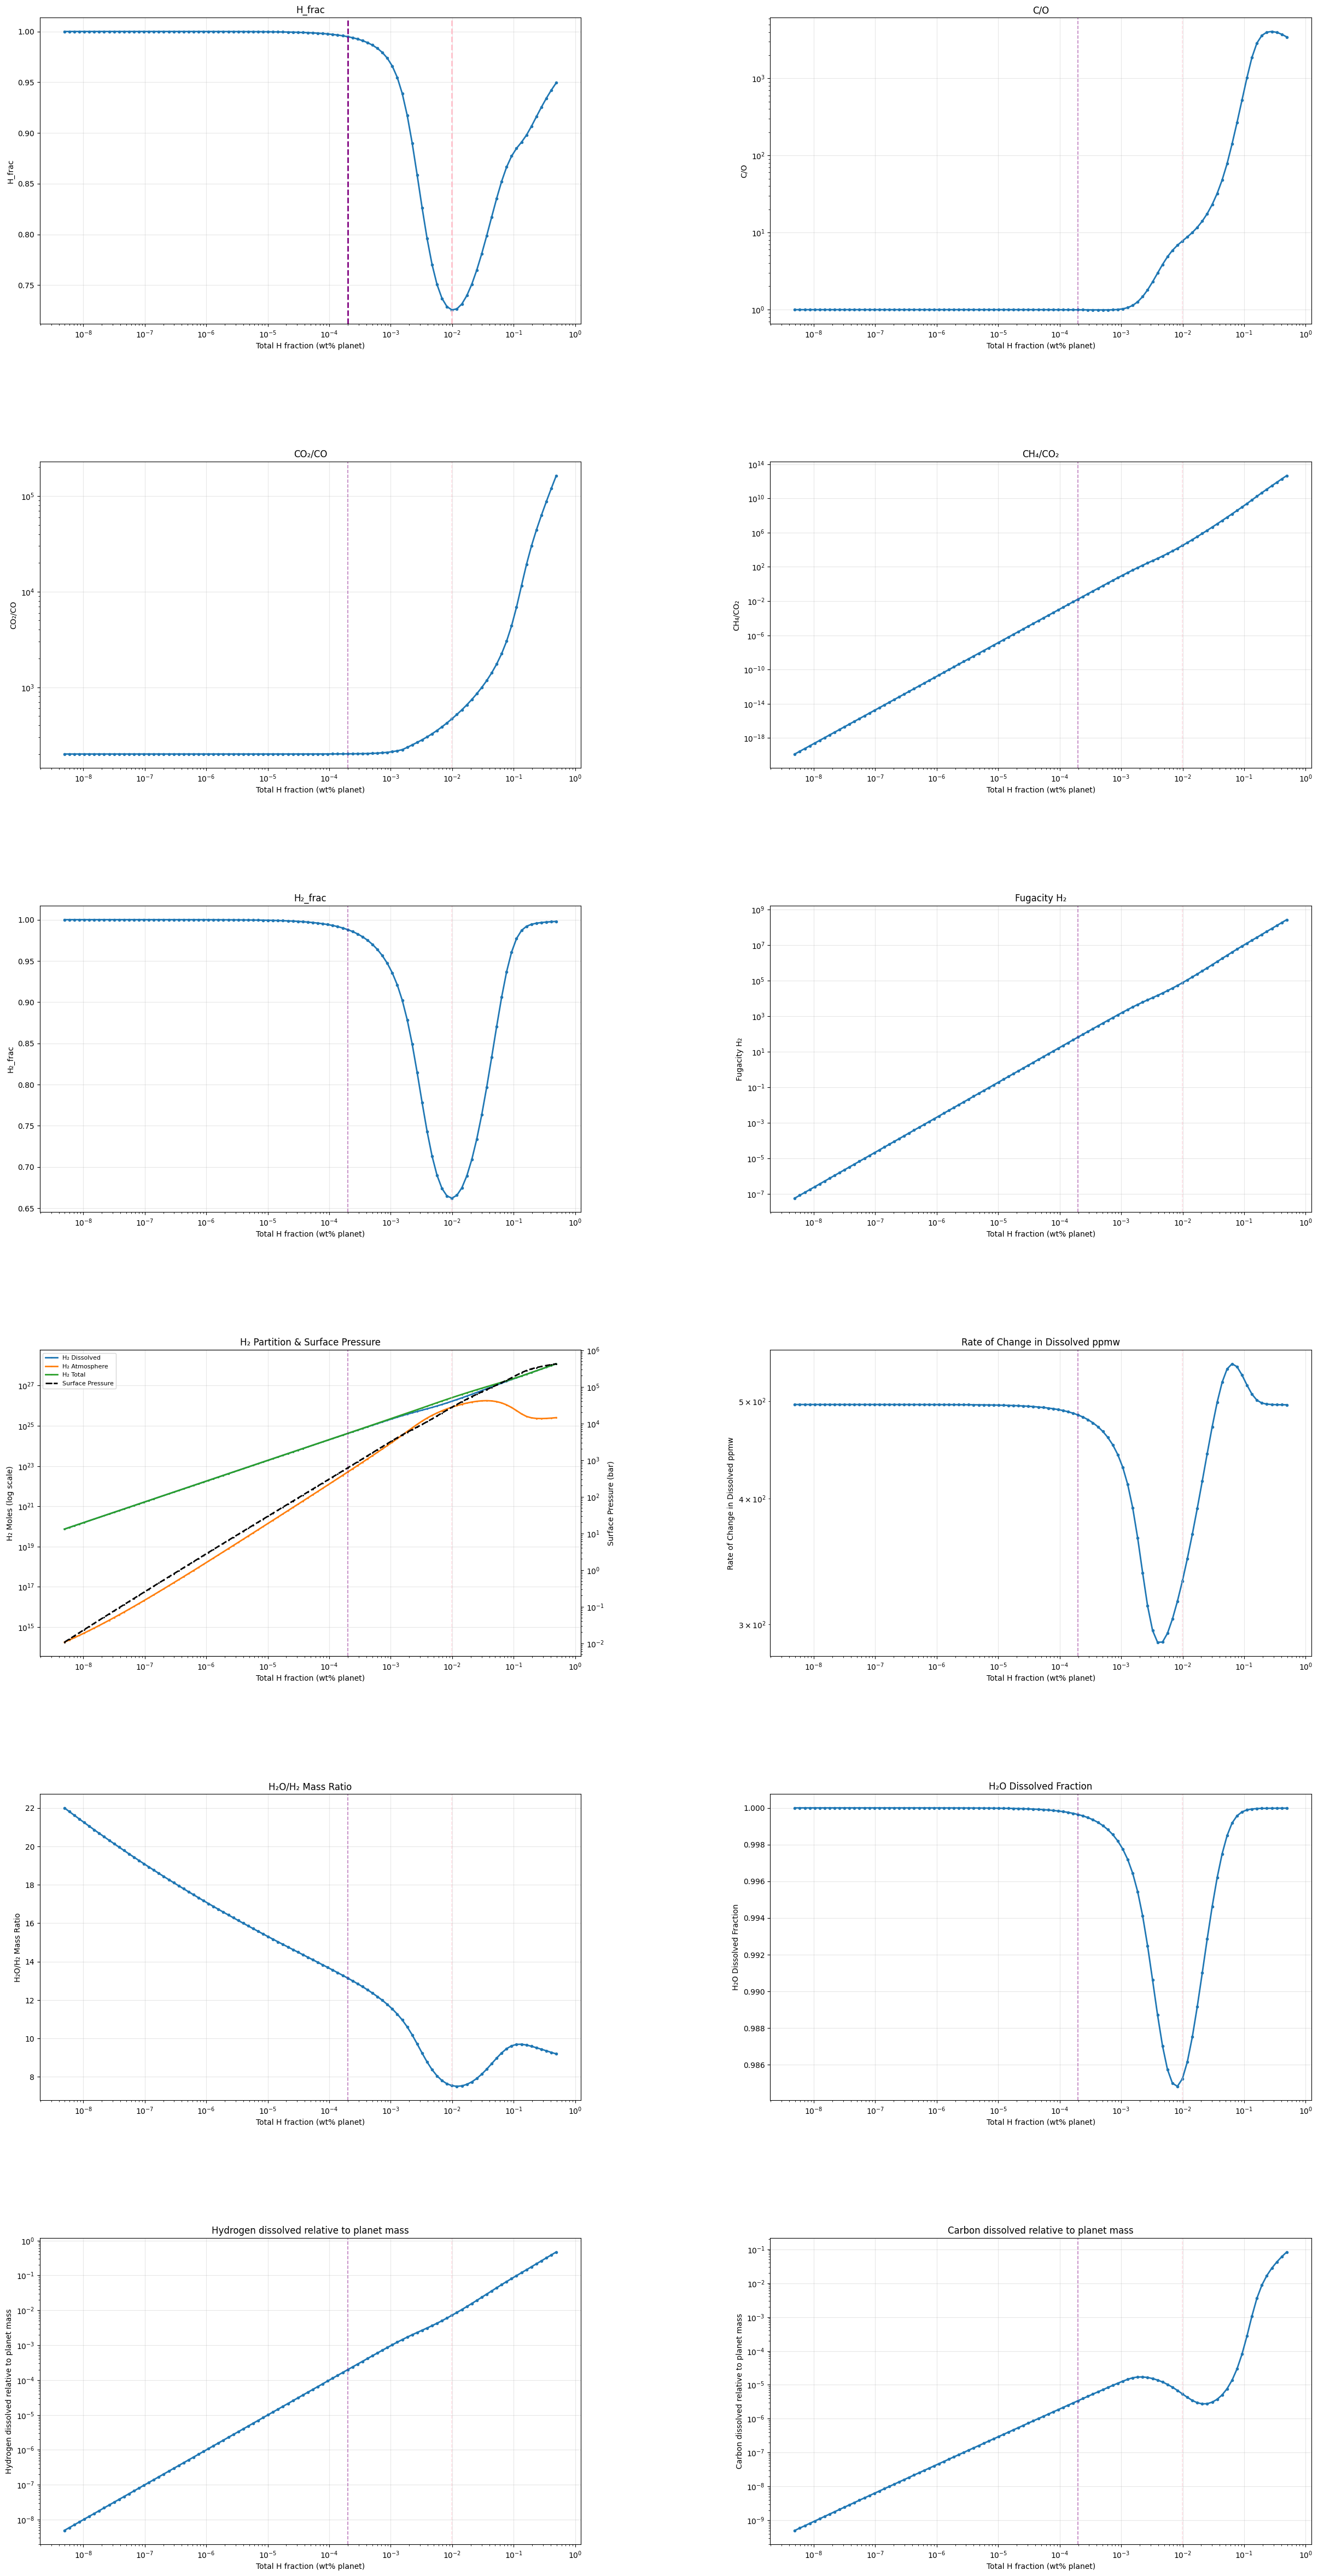


=== Summary ===
H_frac: min at x=9.898e-03, y=7.2550e-01
        max at x=4.926e-09, y=1.0000e+00
C/O: min at x=5.042e-04, y=9.8725e-01
        max at x=2.819e-01, y=4.0631e+03
CO₂/CO: min at x=3.557e-07, y=2.0010e+02
        max at x=4.926e-01, y=1.6384e+05
CH₄/CO₂: min at x=4.926e-09, y=1.2812e-20
        max at x=4.926e-01, y=4.7349e+12
H₂_frac: min at x=9.898e-03, y=6.6221e-01
        max at x=4.926e-09, y=1.0000e+00
Fugacity H₂: min at x=4.926e-09, y=5.7310e-08
        max at x=4.926e-01, y=2.6324e+08
Rate of Change in Dissolved ppmw: min at x=3.904e-03, y=2.8786e+02
        max at x=6.362e-02, y=5.4454e+02
H₂O/H₂ Mass Ratio: min at x=1.192e-02, y=7.5086e+00
        max at x=4.926e-09, y=2.2006e+01
H₂O Dissolved Fraction: min at x=8.217e-03, y=9.8482e-01
        max at x=4.926e-09, y=1.0000e+00
Hydrogen dissolved relative to planet mass: min at x=4.926e-09, y=4.9261e-09
        max at x=4.926e-01, y=4.6772e-01
Carbon dissolved relative to planet mass: min at x=4.926e-09, y=5.0673

{'H_frac': {'min': (0.009897697574255019, 0.7255013991302395),
  'max': (4.926107405969993e-09, 0.9999992944580747)},
 'C/O': {'min': (0.0005042023747216832, 0.987251297369192),
  'max': (0.2818899770640829, 4063.141067387119)},
 'CO₂/CO': {'min': (3.5570480782563585e-07, 200.1001762975897),
  'max': (0.4926107405969993, 163838.48986586157)},
 'CH₄/CO₂': {'min': (4.926107405969993e-09, 1.2812199419010778e-20),
  'max': (0.4926107405969993, 4734858999990.205)},
 'H₂_frac': {'min': (0.009897697574255019, 0.6622068263320247),
  'max': (4.926107405969993e-09, 0.9999975817808991)},
 'Fugacity H₂': {'min': (4.926107405969993e-09, 5.731047918344311e-08),
  'max': (0.4926107405969993, 263242921.1165277)},
 'Rate of Change in Dissolved ppmw': {'min': (0.0039038558746858037,
   287.8647938924051),
  'max': (0.06362312370007889, 544.541638586413)},
 'H₂O/H₂ Mass Ratio': {'min': (0.01192181176860092, 7.508633682869211),
  'max': (4.926107405969993e-09, 22.005722213807577)},
 'H₂O Dissolved Fractio

In [37]:
FUNTION_RUNNER(temperature=3000, radius=6378137 * 3, mantle=1, species=realspecies_withsols, real=True)

[21:07:03 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13')
[21:07:03 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[21:07:03 - atmodeller.classes             - INFO     ] - reactions = {0: '1.0 H2_g + 0.5 O2_g = 1.0 H2O_g',
 1: '0.5 O2_g + 1.0 CO_g = 1.0 CO2_g',
 2: '2.0 H2_g + 1.0 CO_g = 0.5 O2_g + 1.0 CH4_g'}
[21:07:03 - atmodeller.classes             - INFO     ] - Attempting to solve 100 model(s)


2.027680999981892e+26


[21:07:05 - atmodeller.classes             - INFO     ] - Solve complete: 100 (100.00%) successful model(s)
[21:07:05 - atmodeller.classes             - INFO     ] - Solver steps (max) = 74
[21:07:05 - atmodeller.output              - INFO     ] - Writing output to excel
[21:07:05 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[21:07:05 - atmodeller.output_core         - INFO     ] - Computing asdict output
[21:07:05 - atmodeller.output              - INFO     ] - Output written to FILE2.xlsx
[21:07:05 - atmodeller.output              - INFO     ] - Writing output to pickle
[21:07:05 - atmodeller.output              - INFO     ] - Output written to FILE2.pkl
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_76429/3192960051.py:100: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


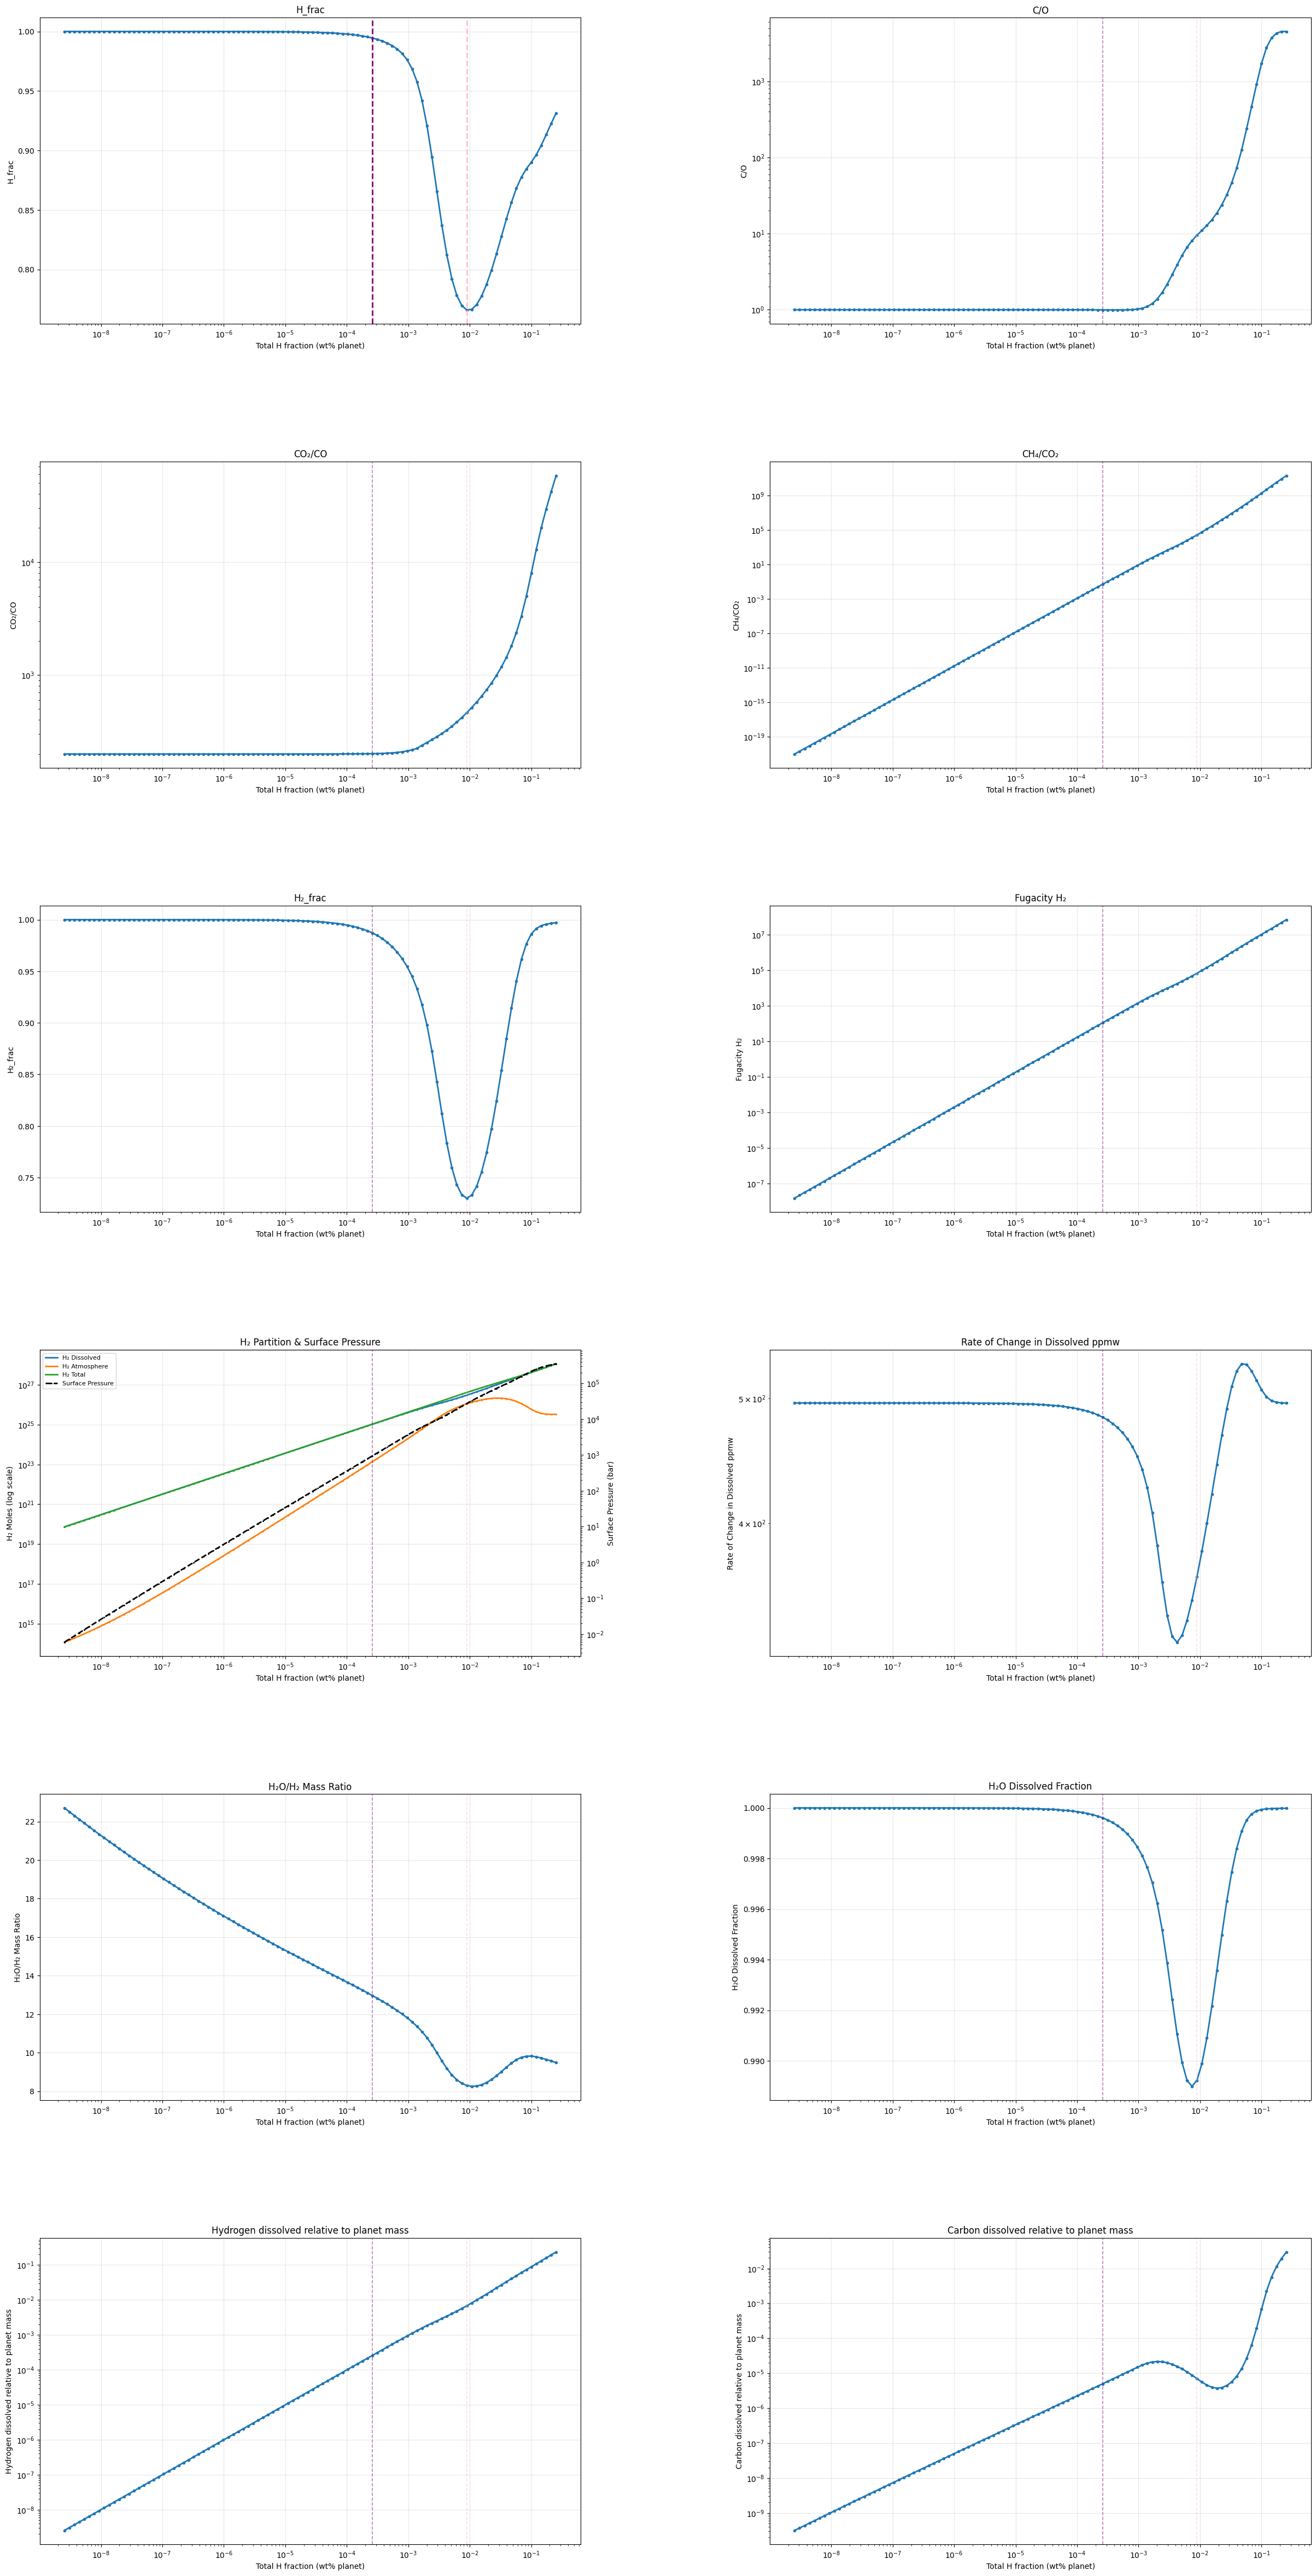


=== Summary ===
H_frac: min at x=8.925e-03, y=7.6599e-01
        max at x=2.542e-09, y=1.0000e+00
C/O: min at x=4.546e-04, y=9.8916e-01
        max at x=2.110e-01, y=4.5222e+03
CO₂/CO: min at x=3.207e-07, y=2.0010e+02
        max at x=2.542e-01, y=5.8121e+04
CH₄/CO₂: min at x=2.542e-09, y=9.4150e-22
        max at x=2.542e-01, y=2.0098e+11
H₂_frac: min at x=8.925e-03, y=7.3009e-01
        max at x=2.542e-09, y=1.0000e+00
Fugacity H₂: min at x=2.542e-09, y=1.5536e-08
        max at x=2.542e-01, y=6.9604e+07
Rate of Change in Dissolved ppmw: min at x=4.240e-03, y=3.2308e+02
        max at x=4.763e-02, y=5.3215e+02
H₂O/H₂ Mass Ratio: min at x=1.075e-02, y=8.2564e+00
        max at x=2.542e-09, y=2.2710e+01
H₂O Dissolved Fraction: min at x=7.410e-03, y=9.8900e-01
        max at x=2.542e-09, y=1.0000e+00
Hydrogen dissolved relative to planet mass: min at x=2.542e-09, y=2.5418e-09
        max at x=2.542e-01, y=2.3676e-01
Carbon dissolved relative to planet mass: min at x=2.542e-09, y=3.1500

{'H_frac': {'min': (0.00892481716715125, 0.7659920980643026),
  'max': (2.541819941127834e-09, 0.9999995472308806)},
 'C/O': {'min': (0.00045464250406470973, 0.989157495084792),
  'max': (0.21102635701525108, 4522.231669905432)},
 'CO₂/CO': {'min': (3.2074129882266253e-07, 200.10017629759832),
  'max': (0.25418199411278336, 58120.70367031082)},
 'CH₄/CO₂': {'min': (2.541819941127834e-09, 9.415008678244224e-22),
  'max': (0.25418199411278336, 200981399458.84164)},
 'H₂_frac': {'min': (0.00892481716715125, 0.730090255410962),
  'max': (2.541819941127834e-09, 0.9999984077852191)},
 'Fugacity H₂': {'min': (2.541819941127834e-09, 1.553576191793209e-08),
  'max': (0.25418199411278336, 69603792.92619792)},
 'Rate of Change in Dissolved ppmw': {'min': (0.004240011209261162,
   323.0843957349959),
  'max': (0.047629064914592976, 532.1516809844711)},
 'H₂O/H₂ Mass Ratio': {'min': (0.010749973873996049, 8.256352970466533),
  'max': (2.541819941127834e-09, 22.710179993357357)},
 'H₂O Dissolved Fra

In [38]:
FUNTION_RUNNER(temperature=3000, radius=6378137 * 4, mantle=1, species=realspecies_withsols, real=True)